In [3]:

from pathlib import Path
import torch

ROOT = Path("/home/sdpl/Downloads/CMX_E2")

# Automatically find the project if the username/path differs
if not ROOT.exists():
    ROOT = Path.home() / "Downloads" / "CMX_E2"

print("E2 folder:", ROOT)
print("Folder exists:", ROOT.exists())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

assert ROOT.exists(), "Bro, check that this notebook is inside CMX_E2!"


E2 folder: /home/cse-sdpl/Downloads/CMX_E2
Folder exists: True
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA RTX 2000 Ada Generation


In [4]:

import re

keywords = re.compile(
    r"class\s+\w*(?:FFM|FRM|Fusion|Rectif)\w*"
    r"|FeatureFusionModule"
    r"|FeatureRectifyModule"
    r"|cross.?modal"
    r"|nn\.Parameter"
    r"|torch\.cat",
    re.IGNORECASE
)

skip = {
    ".git", "__pycache__", "datasets",
    "official_checkpoints", "log_TDD_mit_b2_e1"
}

for file in ROOT.rglob("*.py"):
    if any(part in skip for part in file.parts):
        continue

    try:
        lines = file.read_text(errors="ignore").splitlines()
    except OSError:
        continue

    matches = [
        (i + 1, line.strip())
        for i, line in enumerate(lines)
        if keywords.search(line)
    ]

    if matches:
        print(f"\n{'='*70}")
        print("FILE:", file.relative_to(ROOT))
        for line_no, line in matches:
            print(f"{line_no}: {line[:180]}")



FILE: utils/init_func.py
52: elif isinstance(m, nn.Parameter):

FILE: models/net_utils.py
23: x = torch.cat((x1, x2), dim=1)
26: y = torch.cat((avg, max), dim=1) # B 4C
44: x = torch.cat((x1, x2), dim=1) # B 2C H W
49: class FeatureRectifyModule(nn.Module):
51: super(FeatureRectifyModule, self).__init__()
128: y1 = torch.cat((y1, v1), dim=-1)
129: y2 = torch.cat((y2, v2), dim=-1)
159: class FeatureFusionModule(nn.Module):
186: merge = torch.cat((x1, x2), dim=-1)

FILE: models/encoders/dual_segformer.py
7: from ..net_utils import FeatureFusionModule as FFM
8: from ..net_utils import FeatureRectifyModule as FRM

FILE: models/encoders/dual_segformer_e1.py
7: from ..net_utils import FeatureFusionModule as FFM
8: from ..net_utils import FeatureRectifyModule as FRM

FILE: models/encoders/dual_swin.py
20: from ..net_utils import FeatureFusionModule as FFM
21: from ..net_utils import FeatureRectifyModule as FRM
100: self.relative_position_bias_table = nn.Parameter(
291: x = torch.cat([x0, x1,

original fusion implementation

In [5]:

from pathlib import Path

ROOT = Path.cwd()

# Locate the E2 project even if the notebook is in a subfolder
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "models" / "net_utils.py").exists():
        ROOT = candidate
        break

file = ROOT / "models" / "net_utils.py"
print("Project:", ROOT)
print("Inspecting:", file)

lines = file.read_text().splitlines()

# Display FRM and FFM implementation
for start, end in [(1, 75), (76, 215)]:
    print(f"\n{'='*25} Lines {start}-{end} {'='*25}")
    for i in range(start, min(end, len(lines)) + 1):
        print(f"{i:4}: {lines[i-1]}")


Project: /home/cse-sdpl/Downloads/CMX_E2
Inspecting: /home/cse-sdpl/Downloads/CMX_E2/models/net_utils.py

========================= Lines 1-75 =========================
   1: import torch
   2: import torch.nn as nn
   3: 
   4: from timm.models.layers import trunc_normal_
   5: import math
   6: 
   7: 
   8: # Feature Rectify Module
   9: class ChannelWeights(nn.Module):
  10:     def __init__(self, dim, reduction=1):
  11:         super(ChannelWeights, self).__init__()
  12:         self.dim = dim
  13:         self.avg_pool = nn.AdaptiveAvgPool2d(1)
  14:         self.max_pool = nn.AdaptiveMaxPool2d(1)
  15:         self.mlp = nn.Sequential(
  16:                     nn.Linear(self.dim * 4, self.dim * 4 // reduction),
  17:                     nn.ReLU(inplace=True),
  18:                     nn.Linear(self.dim * 4 // reduction, self.dim * 2), 
  19:                     nn.Sigmoid())
  20: 
  21:     def forward(self, x1, x2):
  22:         B, _, H, W = x1.shape
  23:         x = to

Find how the encoder uses fusion

In [6]:

import re

for relpath in [
    "models/encoders/dual_segformer.py",
    "models/encoders/dual_segformer_e1.py",
]:
    file = ROOT / relpath
    if not file.exists():
        continue

    lines = file.read_text().splitlines()
    print(f"\n{'='*70}\nFILE: {relpath}")

    for i, line in enumerate(lines):
        if re.search(r"\bFRM\b|\bFFM\b|self\.frm|self\.ffm|self\.fusion", line, re.I):
            lo = max(0, i - 3)
            hi = min(len(lines), i + 5)
            for j in range(lo, hi):
                print(f"{j+1:4}: {lines[j]}")
            print("---")



FILE: models/encoders/dual_segformer.py
   4: from functools import partial
   5: 
   6: from timm.models.layers import DropPath, to_2tuple, trunc_normal_
   7: from ..net_utils import FeatureFusionModule as FFM
   8: from ..net_utils import FeatureRectifyModule as FRM
   9: import math
  10: import time
  11: from engine.logger import get_logger
---
   5: 
   6: from timm.models.layers import DropPath, to_2tuple, trunc_normal_
   7: from ..net_utils import FeatureFusionModule as FFM
   8: from ..net_utils import FeatureRectifyModule as FRM
   9: import math
  10: import time
  11: from engine.logger import get_logger
  12: 
---
 317: 
 318:         cur += depths[3]
 319: 
 320:         self.FRMs = nn.ModuleList([
 321:                     FRM(dim=embed_dims[0], reduction=1),
 322:                     FRM(dim=embed_dims[1], reduction=1),
 323:                     FRM(dim=embed_dims[2], reduction=1),
 324:                     FRM(dim=embed_dims[3], reduction=1)])
---
 318:         cur 

In [7]:

from pathlib import Path
import re

ROOT = Path.cwd()

for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "models" / "net_utils.py").exists():
        ROOT = candidate
        break

print("E2 root:", ROOT)

patterns = re.compile(
    r"dual_segformer_e1|dual_segformer|EncoderDecoder|"
    r"backbone|pretrained|resume|load_from",
    re.IGNORECASE
)

for folder in ["configs", "config", "models"]:
    base = ROOT / folder
    if not base.exists():
        continue

    for file in base.rglob("*"):
        if not file.is_file() or file.suffix not in {
            ".py", ".yaml", ".yml", ".json"
        }:
            continue

        try:
            lines = file.read_text(errors="ignore").splitlines()
        except OSError:
            continue

        matches = [
            (i + 1, line.strip())
            for i, line in enumerate(lines)
            if patterns.search(line)
        ]

        if matches:
            print(f"\n--- {file.relative_to(ROOT)} ---")
            for number, line in matches[:15]:
                print(f"{number}: {line[:180]}")


E2 root: /home/cse-sdpl/Downloads/CMX_E2

--- models/builder.py ---
13: class EncoderDecoder(nn.Module):
15: super(EncoderDecoder, self).__init__()
18: # import backbone and decoder
19: if cfg.backbone == 'swin_s':
20: logger.info('Using backbone: Swin-Transformer-small')
21: from .encoders.dual_swin import swin_s as backbone
23: self.backbone = backbone(norm_fuse=norm_layer)
24: elif cfg.backbone == 'swin_b':
25: logger.info('Using backbone: Swin-Transformer-Base')
26: from .encoders.dual_swin import swin_b as backbone
28: self.backbone = backbone(norm_fuse=norm_layer)
29: elif cfg.backbone == 'mit_b5':
30: logger.info('Using backbone: Segformer-B5')
31: from .encoders.dual_segformer import mit_b5 as backbone
32: self.backbone = backbone(norm_fuse=norm_layer)

--- models/encoders/dual_segformer.py ---
349: def init_weights(self, pretrained=None):
350: if isinstance(pretrained, str):
351: load_dualpath_model(self, pretrained)
353: raise TypeError('pretrained must be a str or None')

--

In [8]:

from pathlib import Path
import re

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E2")

for folder_name in ["configs", "config"]:
    folder = ROOT / folder_name
    if not folder.exists():
        continue

    for file in folder.rglob("*"):
        if file.suffix not in {".py", ".yaml", ".yml"}:
            continue

        text = file.read_text(errors="ignore")
        if any(key in text.lower() for key in [
            "mit_b2", "mit_b5", "backbone", "norm_fuse"
        ]):
            print(f"\n--- {file.relative_to(ROOT)} ---")
            for i, line in enumerate(text.splitlines(), 1):
                if re.search(
                    r"mit_b2|mit_b5|backbone|norm_fuse|pretrained",
                    line, re.I
                ):
                    print(f"{i}: {line.strip()}")


In [9]:

files = [
    ROOT / "models/encoders/dual_segformer.py",
    ROOT / "models/encoders/dual_segformer_e1.py",
]

for file in files:
    print(f"\n--- {file.name} ---")
    lines = file.read_text(errors="ignore").splitlines()

    for i in range(315, min(435, len(lines))):
        if i < len(lines) and (
            "FRM" in lines[i]
            or "FFM" in lines[i]
            or "x_fused" in lines[i]
            or "outs.append" in lines[i]
        ):
            print(f"{i+1}: {lines[i].strip()}")



--- dual_segformer.py ---
320: self.FRMs = nn.ModuleList([
321: FRM(dim=embed_dims[0], reduction=1),
322: FRM(dim=embed_dims[1], reduction=1),
323: FRM(dim=embed_dims[2], reduction=1),
324: FRM(dim=embed_dims[3], reduction=1)])
326: self.FFMs = nn.ModuleList([
327: FFM(dim=embed_dims[0], reduction=1, num_heads=num_heads[0], norm_layer=norm_fuse),
328: FFM(dim=embed_dims[1], reduction=1, num_heads=num_heads[1], norm_layer=norm_fuse),
329: FFM(dim=embed_dims[2], reduction=1, num_heads=num_heads[2], norm_layer=norm_fuse),
330: FFM(dim=embed_dims[3], reduction=1, num_heads=num_heads[3], norm_layer=norm_fuse)])
376: x_rgb, x_e = self.FRMs[0](x_rgb, x_e)
377: x_fused = self.FFMs[0](x_rgb, x_e)
378: outs.append(x_fused)
393: x_rgb, x_e = self.FRMs[1](x_rgb, x_e)
394: x_fused = self.FFMs[1](x_rgb, x_e)
395: outs.append(x_fused)
410: x_rgb, x_e = self.FRMs[2](x_rgb, x_e)
411: x_fused = self.FFMs[2](x_rgb, x_e)
412: outs.append(x_fused)
427: x_rgb, x_e = self.FRMs[3](x_rgb, x_e)
428: x_fused = 

In [10]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E2")

print("Project exists:", ROOT.exists())
print("\nTop-level files and folders:")

for item in sorted(ROOT.iterdir()):
    print(("DIR " if item.is_dir() else "FILE"), item.name)

print("\nPossible configuration files:")
for p in ROOT.rglob("*"):
    if p.is_file() and (
        "config" in p.name.lower()
        or p.suffix in {".yaml", ".yml"}
    ):
        if not any(part in {
            ".git", "__pycache__", "datasets", "checkpoints"
        } for part in p.parts):
            print(p.relative_to(ROOT))


Project exists: True

Top-level files and folders:
FILE .gitignore
DIR  .ipynb_checkpoints
DIR  .venv
FILE CMX_Official_Baseline_Comparison.ipynb
FILE CMX_Original_Test.ipynb
FILE E2_Learnable_Weighted_Fusion.ipynb
FILE LICENSE
FILE README.md
DIR  __pycache__
FILE config.py
DIR  dataloader
DIR  datasets
DIR  e1_predictions
DIR  e1_predictions_color
DIR  engine
FILE eval.ipynb
FILE eval.py
DIR  log_TDD_mit_b2_e1
DIR  models
DIR  official_checkpoints
DIR  predictions_TDD_epoch100
DIR  predictions_TDD_epoch100_color
DIR  pretrained
FILE requirements.txt
FILE segmentation.jpg
FILE train.py
FILE train.py.backup
DIR  utils

Possible configuration files:
config.py
.venv/lib64/python3.14/site-packages/pip/_internal/configuration.py
.venv/lib64/python3.14/site-packages/pip/_internal/commands/configuration.py
.venv/lib64/python3.14/site-packages/pip/_internal/locations/_sysconfig.py
.venv/lib/python3.14/site-packages/pip/_internal/configuration.py
.venv/lib/python3.14/site-packages/pip/_internal

In [11]:

import re

for name in ["train.py", "train.sh", "test.py"]:
    p = ROOT / name
    if not p.exists():
        continue

    print(f"\n--- {name} ---")
    lines = p.read_text(errors="ignore").splitlines()

    for i, line in enumerate(lines, 1):
        if re.search(
            r"config|argparse|mit_b2|mit_b5|backbone|load_from|"
            r"pretrained|EncoderDecoder",
            line, re.I
        ):
            print(f"{i}: {line.strip()}")



--- train.py ---
5: import argparse
14: from config import config
16: from models.builder import EncoderDecoder as segmodel
26: parser = argparse.ArgumentParser()
35: seed = config.seed
46: tb_dir = config.tb_dir + '/{}'.format(time.strftime("%b%d_%d-%H-%M", time.localtime()))
47: generate_tb_dir = config.tb_dir + '/tb'
51: # config network and criterion
52: criterion = nn.CrossEntropyLoss(reduction='mean', ignore_index=config.background)
59: model=segmodel(cfg=config, criterion=criterion, norm_layer=BatchNorm2d)
61: # group weight and config optimizer
62: base_lr = config.lr
64: base_lr = config.lr
69: if config.optimizer == 'AdamW':
70: optimizer = torch.optim.AdamW(params_list, lr=base_lr, betas=(0.9, 0.999), weight_decay=config.weight_decay)
71: elif config.optimizer == 'SGDM':
72: optimizer = torch.optim.SGD(params_list, lr=base_lr, momentum=config.momentum, weight_decay=config.weight_decay)
76: # config lr policy
77: total_iteration = config.nepochs * config.niters_per_epoch
78:

In [12]:

from pathlib import Path
import re

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E2")
p = ROOT / "config.py"

lines = p.read_text(errors="ignore").splitlines()

print("CONFIGURATION:", p)
for i, line in enumerate(lines, 1):
    if re.search(
        r"backbone|mit_b2|mit_b5|pretrained|checkpoint|"
        r"nepochs|niters_per_epoch|lr\s*=|dataset|"
        r"train_source|eval_source|batch_size|"
        r"checkpoint_dir|log_dir",
        line, re.I
    ):
        print(f"{i:3}: {line.strip()}")


CONFIGURATION: /home/cse-sdpl/Downloads/CMX_E2/config.py
 23: # DATASET CONFIGURATION: TDD RGB-THERMAL
 25: C.dataset_name = 'TDD'
 26: C.dataset_path = osp.join(C.root_dir, 'datasets', 'TDD')
 29: C.rgb_root_folder = osp.join(C.dataset_path, 'RGB')
 33: C.gt_root_folder = osp.join(C.dataset_path, 'Label')
 38: C.x_root_folder = osp.join(C.dataset_path, 'Thermal')
 42: # Dataset split files
 43: C.train_source = osp.join(C.dataset_path, 'train.txt')
 44: C.eval_source = osp.join(C.dataset_path, 'val.txt')
 47: # Dataset sizes
 80: C.backbone = 'mit_b2_e1'
 82: C.pretrained_model = osp.join(
 84: 'pretrained',
 86: 'mit_b2.pth'
 95: C.lr = 6e-5
102: C.batch_size = 2
103: C.nepochs = 100
104: C.niters_per_epoch = C.num_train_imgs // C.batch_size + 1
124: # CHECKPOINT CONFIGURATION
126: C.checkpoint_start_epoch = 1
127: C.checkpoint_step = 5
141: C.log_dir = osp.abspath(
142: 'log_' + C.dataset_name + '_' + C.backbone
145: C.tb_dir = osp.join(C.log_dir, 'tb')
146: C.log_dir_link = C.log_d

In [13]:

p = ROOT / "models" / "builder.py"
lines = p.read_text(errors="ignore").splitlines()

print("MODEL BUILDER:", p)
for i, line in enumerate(lines, 1):
    print(f"{i:3}: {line}")


MODEL BUILDER: /home/cse-sdpl/Downloads/CMX_E2/models/builder.py
  1: import torch
  2: import torch.nn as nn
  3: import torch.nn.functional as F
  4: 
  5: from utils.init_func import init_weight
  6: from utils.load_utils import load_pretrain
  7: from functools import partial
  8: 
  9: from engine.logger import get_logger
 10: 
 11: logger = get_logger()
 12: 
 13: class EncoderDecoder(nn.Module):
 14:     def __init__(self, cfg=None, criterion=nn.CrossEntropyLoss(reduction='mean', ignore_index=255), norm_layer=nn.BatchNorm2d):
 15:         super(EncoderDecoder, self).__init__()
 16:         self.channels = [64, 128, 320, 512]
 17:         self.norm_layer = norm_layer
 18:         # import backbone and decoder
 19:         if cfg.backbone == 'swin_s':
 20:             logger.info('Using backbone: Swin-Transformer-small')
 21:             from .encoders.dual_swin import swin_s as backbone
 22:             self.channels = [96, 192, 384, 768]
 23:             self.backbone = backbone

In [14]:

for folder in [
    ROOT / "log_TDD_mit_b2_e1",
    ROOT / "official_checkpoints",
    ROOT / "pretrained",
]:
    print(f"\n--- {folder.name} ---")
    if folder.exists():
        for item in sorted(folder.iterdir()):
            print(("DIR " if item.is_dir() else "FILE"), item.name)



--- log_TDD_mit_b2_e1 ---
DIR  checkpoint
DIR  tb
FILE val_2026_10_13_10_17_42.log
FILE val_last.log

--- official_checkpoints ---
FILE MFNet-MiT-B2.pth

--- pretrained ---
DIR  segformer


our active configuration uses:
- Backbone: mit_b2_e1 — MiT-B2 with the E1 encoder.
- Pretrained weights: configured through config.py.
- Dataset: TDD RGB–thermal.
- Training: 100 epochs, batch size 2.
- E1 encoder: dual_segformer_e1.py, which bypasses FRM at all four stages.

pretrained checkpoint and E1 model files

In [15]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E2")

print("=== Pretrained files ===")
for folder in [ROOT / "pretrained", ROOT / "official_checkpoints"]:
    if folder.exists():
        for p in folder.rglob("*"):
            if p.is_file():
                print(p.relative_to(ROOT))

print("\n=== E1 checkpoints ===")
ckpt_dir = ROOT / "log_TDD_mit_b2_e1" / "checkpoint"
if ckpt_dir.exists():
    for p in sorted(ckpt_dir.iterdir()):
        print(p.name, f"({p.stat().st_size / 1024**2:.1f} MB)")

print("\n=== Relevant config values ===")
lines = (ROOT / "config.py").read_text().splitlines()
for i in range(74, 90):
    if i < len(lines):
        print(f"{i+1}: {lines[i]}")


=== Pretrained files ===
pretrained/segformer/mit_b2.pth
official_checkpoints/MFNet-MiT-B2.pth

=== E1 checkpoints ===
epoch-10.pth (686.2 MB)
epoch-100.pth (686.3 MB)
epoch-15.pth (686.2 MB)
epoch-20.pth (686.2 MB)
epoch-25.pth (686.2 MB)
epoch-30.pth (686.2 MB)
epoch-35.pth (686.2 MB)
epoch-40.pth (686.2 MB)
epoch-45.pth (686.2 MB)
epoch-5.pth (686.2 MB)
epoch-50.pth (686.2 MB)
epoch-55.pth (686.2 MB)
epoch-60.pth (686.2 MB)
epoch-65.pth (686.2 MB)
epoch-70.pth (686.2 MB)
epoch-75.pth (686.2 MB)
epoch-80.pth (686.2 MB)
epoch-85.pth (686.2 MB)
epoch-90.pth (686.2 MB)
epoch-95.pth (686.2 MB)
epoch-last.pth (686.3 MB)

=== Relevant config values ===
75: 
76: # ============================================================
77: # NETWORK CONFIGURATION
78: # ============================================================
79: # Network Configuration
80: C.backbone = 'mit_b2_e1'
81: 
82: C.pretrained_model = osp.join(
83:     C.root_dir,
84:     'pretrained',
85:     'segformer',
86:     'mit_b2.

ur exact E2 change
We'll implement the Option B experiment as follows:
1. Copy dual_segformer_e1.py to a new dual_segformer_e2.py.
2. Restore the original FRM calls in the E2 encoder.
3. Add two learnable logits to the FFM and normalize them with softmax.
4. Weight the cross-attention-updated feature streams before the existing channel-embedding fusion.
5. Route mit_b2_e2 to the new encoder, leaving E1 unchanged.
The fusion modification will be:
\[
(a_R,a_T)=\operatorname{softmax}(\alpha_R,\alpha_T)
\]

\[
\widetilde F_R=a_RF_R',\qquad
\widetilde F_T=a_TF_T'
\]

\[
F_{\mathrm{fused}}
=\operatorname{ChannelEmbed}
\left(\operatorname{Concat}(\widetilde F_R,\widetilde F_T)\right)
\]

Here, \(F_R'\) and \(F_T'\) are the features after CMX cross-attention. This preserves the existing fusion projection rather than replacing it with simple addition.

In [16]:

from pathlib import Path
import shutil

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E2")
NET_UTILS = ROOT / "models" / "net_utils.py"

assert ROOT.exists(), f"E2 project not found: {ROOT}"
assert NET_UTILS.exists(), f"Missing file: {NET_UTILS}"

source = NET_UTILS.read_text()

# Avoid duplicate edits if this cell is rerun.
if "class WeightedFeatureFusionModule" in source:
    print("E2 weighted fusion class already exists; no change made.")
else:
    backup = NET_UTILS.with_suffix(".py.e2_backup")
    shutil.copy2(NET_UTILS, backup)

    new_class = '''

# E2: Learnable Weighted Cross-Attention Fusion
class WeightedFeatureFusionModule(FeatureFusionModule):
    """
    Preserve CMX cross-attention and ChannelEmbed.
    Add global learnable RGB/thermal weights after cross-attention.
    """
    def __init__(self, dim, reduction=1, num_heads=None,
                 norm_layer=nn.BatchNorm2d):
        super().__init__(
            dim=dim,
            reduction=reduction,
            num_heads=num_heads,
            norm_layer=norm_layer
        )
        # Equal initial contribution: softmax([0, 0]) = [0.5, 0.5]
        self.modality_logits = nn.Parameter(torch.zeros(2))

    def forward(self, x1, x2):
        B, C, H, W = x1.shape

        x1 = x1.flatten(2).transpose(1, 2)
        x2 = x2.flatten(2).transpose(1, 2)

        # Original CMX cross-modal interaction
        x1, x2 = self.cross(x1, x2)

        # E2: learned global modality weighting
        weights = torch.softmax(self.modality_logits, dim=0)
        x1 = weights[0] * x1
        x2 = weights[1] * x2

        # Preserve original CMX channel embedding and output dimensions
        merge = torch.cat((x1, x2), dim=-1)
        merge = self.channel_emb(merge, H, W)

        return merge
'''

    NET_UTILS.write_text(source.rstrip() + "\n" + new_class)
    print("Added WeightedFeatureFusionModule.")
    print("Backup:", backup)


Added WeightedFeatureFusionModule.
Backup: /home/cse-sdpl/Downloads/CMX_E2/models/net_utils.py.e2_backup


In [17]:

import re
import shutil

E1_ENCODER = ROOT / "models" / "encoders" / "dual_segformer_e1.py"
E2_ENCODER = ROOT / "models" / "encoders" / "dual_segformer_e2.py"

assert E1_ENCODER.exists(), f"Missing E1 encoder: {E1_ENCODER}"

if E2_ENCODER.exists():
    print("E2 encoder already exists. Inspect it before overwriting.")
else:
    shutil.copy2(E1_ENCODER, E2_ENCODER)
    print("Created:", E2_ENCODER)

text = E2_ENCODER.read_text()

# Use the new E2 fusion class only in the E2 encoder.
old_import = "from ..net_utils import FeatureFusionModule as FFM"
new_import = "from ..net_utils import WeightedFeatureFusionModule as FFM"

if old_import in text:
    text = text.replace(old_import, new_import, 1)
elif new_import not in text:
    raise RuntimeError("Could not identify the FFM import. No further changes made.")

# Restore FRM before FFM in each of the four E1-bypassed stages.
for stage in range(1, 5):
    pattern = (
        rf"(?m)^(?P<indent>\s*)# E1: FRM bypassed at stage {stage}\s*\n"
        rf"(?P=indent)x_fused = self\.FFMs\[{stage-1}\]\(x_rgb, x_e\)"
    )
    replacement = (
        rf"\g<indent># E2: restore original CMX FRM at stage {stage}\n"
        rf"\g<indent>x_rgb, x_e = self.FRMs[{stage-1}](x_rgb, x_e)\n"
        rf"\g<indent>x_fused = self.FFMs[{stage-1}](x_rgb, x_e)"
    )
    text, count = re.subn(pattern, replacement, text)
    if count != 1:
        raise RuntimeError(
            f"Expected exactly one E1 bypass at stage {stage}, found {count}. "
            "Review the encoder file before proceeding."
        )

E2_ENCODER.write_text(text)

print("E2 encoder updated.")
print("FRM restored at stages 1–4.")
print("E2 fusion class selected.")


Created: /home/cse-sdpl/Downloads/CMX_E2/models/encoders/dual_segformer_e2.py
E2 encoder updated.
FRM restored at stages 1–4.
E2 fusion class selected.


In [18]:

BUILDER = ROOT / "models" / "builder.py"
CONFIG = ROOT / "config.py"

assert BUILDER.exists() and CONFIG.exists()

builder_text = BUILDER.read_text()
config_text = CONFIG.read_text()

# Add a dedicated E2 branch before the existing E1 branch.
e1_branch = """        elif cfg.backbone == 'mit_b2_e1':
            logger.info('Using E1: SegFormer-B2 without FRM')
            from .encoders.dual_segformer_e1 import mit_b2 as backbone
            self.backbone = backbone(norm_fuse=norm_layer)
"""

e2_branch = """        elif cfg.backbone == 'mit_b2_e2':
            logger.info('Using E2: SegFormer-B2 with FRM and weighted cross-attention fusion')
            from .encoders.dual_segformer_e2 import mit_b2 as backbone
            self.backbone = backbone(norm_fuse=norm_layer)
"""

if "cfg.backbone == 'mit_b2_e2'" not in builder_text:
    if e1_branch not in builder_text:
        raise RuntimeError("Could not find the exact E1 builder branch.")
    shutil.copy2(BUILDER, BUILDER.with_suffix(".py.e2_backup"))
    builder_text = builder_text.replace(e1_branch, e2_branch + e1_branch, 1)
    BUILDER.write_text(builder_text)

if "C.backbone = 'mit_b2_e2'" not in config_text:
    if "C.backbone = 'mit_b2_e1'" not in config_text:
        raise RuntimeError("Could not find the active E1 backbone setting.")
    shutil.copy2(CONFIG, CONFIG.with_suffix(".py.e2_backup"))
    config_text = config_text.replace(
        "C.backbone = 'mit_b2_e1'",
        "C.backbone = 'mit_b2_e2'",
        1
    )
    CONFIG.write_text(config_text)

print("Builder routes mit_b2_e2 to dual_segformer_e2.py")
print("E2 config now selects mit_b2_e2")
print("Pretrained checkpoint path and training settings were not changed.")


Builder routes mit_b2_e2 to dual_segformer_e2.py
E2 config now selects mit_b2_e2
Pretrained checkpoint path and training settings were not changed.


In [19]:

# Structural verification — no PyTorch import required
checks = {
    "E2 fusion class": "class WeightedFeatureFusionModule" in NET_UTILS.read_text(),
    "E2 encoder uses weighted fusion": (
        "WeightedFeatureFusionModule as FFM" in E2_ENCODER.read_text()
    ),
    "E2 builder route": "cfg.backbone == 'mit_b2_e2'" in BUILDER.read_text(),
    "E2 active config": "C.backbone = 'mit_b2_e2'" in CONFIG.read_text(),
}

encoder_text = E2_ENCODER.read_text()
for stage in range(4):
    checks[f"FRM stage {stage+1}"] = (
        f"self.FRMs[{stage}](x_rgb, x_e)" in encoder_text
    )

for name, passed in checks.items():
    print(("PASS" if passed else "FAIL"), name)

assert all(checks.values()), "A structural check failed. Do not train yet."
print("\nAll structural checks passed.")


PASS E2 fusion class
PASS E2 encoder uses weighted fusion
PASS E2 builder route
PASS E2 active config
PASS FRM stage 1
PASS FRM stage 2
PASS FRM stage 3
PASS FRM stage 4

All structural checks passed.


checkpoint loading before training

In [21]:
import os
import torch
from pathlib import Path

PROJECT_DIR = Path("/home/cse-sdpl/Downloads/CMX_E2")
os.chdir(PROJECT_DIR)

print("Project:", Path.cwd())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

from config import config

print("\nDataset:", config.dataset_name)
print("Backbone:", config.backbone)
print("Epochs:", config.nepochs)
print("Batch size:", config.batch_size)
print("Pretrained weights exist:", Path(config.pretrained_model).is_file())

Project: /home/cse-sdpl/Downloads/CMX_E2
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA RTX 2000 Ada Generation
GPU memory: 15.57 GB

Dataset: TDD
Backbone: mit_b2_e2
Epochs: 100
Batch size: 2
Pretrained weights exist: True


In [22]:

import os
import subprocess
import threading
from IPython.display import display, HTML

PROJECT_DIR = "/home/cse-sdpl/Downloads/CMX_E2"

# Prevent accidentally starting two training processes from this notebook.
if "e2_process" in globals() and e2_process.poll() is None:
    print("E2 training is already running. Do not launch another process.")
else:
    e2_process = subprocess.Popen(
        [
            "conda", "run", "--no-capture-output",
            "-n", "cmx", "python", "-u", "train.py"
        ],
        cwd=PROJECT_DIR,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    print("E2 training process launched.")
    print("PID:", e2_process.pid)
    print("Training logs will appear in the next cell.")


E2 training process launched.
PID: 192588
Training logs will appear in the next cell.


In [23]:

import time
from IPython.display import clear_output, display

if "e2_process" not in globals():
    print("Launch training first.")
else:
    print("Streaming E2 training logs...\n")
    for line in iter(e2_process.stdout.readline, ""):
        print(line, end="", flush=True)

    return_code = e2_process.wait()
    print(f"\nTraining process exited with code: {return_code}")


Streaming E2 training logs...

13 12:12:59 PyTorch Version 2.14.1+cu130
Traceback (most recent call last):
  File "/home/cse-sdpl/Downloads/CMX_E2/train.py", line 31, in <module>
    with Engine(custom_parser=parser) as engine:
  File "/home/cse-sdpl/Downloads/CMX_E2/engine/engine.py", line 59, in __init__
    self.devices = parse_devices(self.args.devices)
  File "/home/cse-sdpl/Downloads/CMX_E2/utils/pyt_utils.py", line 211, in parse_devices
    device = int(d)
ValueError: invalid literal for int() with base 10: ''
ERROR conda.cli.main_run:execute(148): `conda run python -u train.py` failed. (See above for error)

Training process exited with code: 1


In [24]:
from pathlib import Path

project = Path("/home/cse-sdpl/Downloads/CMX_E2")

for filename in ["config.py", "train.py", "engine/engine.py", "utils/pyt_utils.py"]:
    path = project / filename
    print(f"\n--- {filename} ---")
    lines = path.read_text().splitlines()

    for i, line in enumerate(lines, start=1):
        if any(key in line.lower() for key in ["devices", "parse_devices", "argparse"]):
            print(f"{i}: {line}")


--- config.py ---
8: import argparse
175:     parser = argparse.ArgumentParser()

--- train.py ---
5: import argparse
26: parser = argparse.ArgumentParser()

--- engine/engine.py ---
4: import argparse
10: from utils.pyt_utils import load_model, parse_devices, extant_file, link_file, ensure_dir
34:         self.devices = None
38:             self.parser = argparse.ArgumentParser()
40:             assert isinstance(custom_parser, argparse.ArgumentParser)
57:             self.devices = [i for i in range(self.world_size)]
59:             self.devices = parse_devices(self.args.devices)
64:         p.add_argument('-d', '--devices', default='',

--- utils/pyt_utils.py ---
6: import argparse
194: def parse_devices(input_devices):
195:     if input_devices.endswith('*'):
196:         devices = list(range(torch.cuda.device_count()))
197:         return devices
199:     devices = []
200:     for d in input_devices.split(','):
209:                 devices.append(sd)
213:             devices.appe

In [25]:
import sys
print("Notebook Python:", sys.executable)

import subprocess
result = subprocess.run(
    [
        "conda", "run", "--no-capture-output", "-n", "cmx",
        "python", "train.py", "--help"
    ],
    cwd="/home/cse-sdpl/Downloads/CMX_E2",
    capture_output=True,
    text=True,
    timeout=60
)
print(result.stdout[-5000:])
print(result.stderr[-2000:])

Notebook Python: /home/cse-sdpl/miniconda3/envs/cmx/bin/python
usage: train.py [-h] [-d DEVICES] [-c FILE] [--local_rank LOCAL_RANK]
                [-p PORT]

options:
  -h, --help            show this help message and exit
  -d DEVICES, --devices DEVICES
                        set data parallel training
  -c FILE, --continue FILE
                        continue from one certain checkpoint
  --local_rank LOCAL_RANK
                        process rank on node
  -p PORT, --port PORT  port for init_process_group

13 12:13:54 PyTorch Version 2.14.1+cu130



In [26]:

import subprocess

PROJECT_DIR = "/home/cse-sdpl/Downloads/CMX_E2"

if "e2_process" in globals() and e2_process.poll() is None:
    print("E2 training is already running. Do not start another process.")
else:
    e2_process = subprocess.Popen(
        [
            "conda", "run", "--no-capture-output",
            "-n", "cmx",
            "python", "-u", "train.py",
            "-d", "0"
        ],
        cwd=PROJECT_DIR,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    print("E2 process launched with GPU 0.")
    print("PID:", e2_process.pid)


E2 process launched with GPU 0.
PID: 192789


In [27]:

if "e2_process" not in globals():
    print("Launch E2 training first.")
else:
    for line in iter(e2_process.stdout.readline, ""):
        print(line, end="", flush=True)

    print("\nTraining process exit code:", e2_process.wait())


13 12:15:23 PyTorch Version 2.14.1+cu130
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
13 12:15:23 using devices 0
13 12:15:25 Using E2: SegFormer-B2 with FRM and weighted cross-attention fusion
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
13 12:15:27 Using MLP Decoder
13 12:15:27 Loading pretrained model: /home/cse-sdpl/Downloads/CMX_E2/pretrained/segformer/mit_b2.pth
13 12:15:27 Load model, Time usage:
	IO: 0.052481889724731445, initialize parameters: 0.027406930923461914
13 12:15:27 Initing weights ...
13 12:15:27 E2 optimizer fix: added 4 missing trainable parameter tensors with zero weight decay.
13 12:15:27 begin 

Epoch 1/100 Iter 73/785: lr=5.5032e-07 loss=2.1886 total_loss=2.1139: [00:34<04:42, 2.52it/s]
Epoch 1/100 Iter 74/785: lr=5.5796e-07 loss=2.3353 total_loss=2.1169: [00:34<04:44, 2.50it/s]
Epoch 1/100 Iter 75/785: lr=5.6561e-07 loss=1.9777 total_loss=2.1150: [00:35<04:49, 2.45it/s]
Epoch 1/100 Iter 76/785: lr=5.7325e-07 loss=1.9605 total_loss=2.1130: [00:35<04:47, 2.47it/s]
Epoch 1/100 Iter 77/785: lr=5.8089e-07 loss=2.4998 total_loss=2.1180: [00:35<04:45, 2.48it/s]
Epoch 1/100 Iter 78/785: lr=5.8854e-07 loss=1.7566 total_loss=2.1134: [00:36<04:43, 2.50it/s]
Epoch 1/100 Iter 79/785: lr=5.9618e-07 loss=1.7527 total_loss=2.1088: [00:36<04:41, 2.51it/s]
Epoch 1/100 Iter 80/785: lr=6.0382e-07 loss=2.4035 total_loss=2.1125: [00:37<04:40, 2.51it/s]
Epoch 1/100 Iter 81/785: lr=6.1146e-07 loss=2.3362 total_loss=2.1153: [00:37<04:40, 2.51it/s]
Epoch 1/100 Iter 82/785: lr=6.1911e-07 loss=2.4930 total_loss=2.1199: [00:37<04:39, 2.51it/s]
Epoch 1/100 Iter 83/785: lr=6.2675e-07 loss=2.3005 total_los

Epoch 1/100 Iter 160/785: lr=1.2153e-06 loss=1.6278 total_loss=2.0263: [01:09<04:14, 2.46it/s]
Epoch 1/100 Iter 161/785: lr=1.2229e-06 loss=2.4184 total_loss=2.0287: [01:09<04:16, 2.43it/s]
Epoch 1/100 Iter 162/785: lr=1.2306e-06 loss=1.7644 total_loss=2.0271: [01:10<04:19, 2.40it/s]
Epoch 1/100 Iter 163/785: lr=1.2382e-06 loss=1.3256 total_loss=2.0228: [01:10<04:21, 2.38it/s]
Epoch 1/100 Iter 164/785: lr=1.2459e-06 loss=2.4168 total_loss=2.0252: [01:10<04:21, 2.38it/s]
Epoch 1/100 Iter 165/785: lr=1.2535e-06 loss=1.2400 total_loss=2.0204: [01:11<04:20, 2.38it/s]
Epoch 1/100 Iter 166/785: lr=1.2611e-06 loss=1.7035 total_loss=2.0185: [01:11<04:16, 2.41it/s]
Epoch 1/100 Iter 167/785: lr=1.2688e-06 loss=2.1977 total_loss=2.0196: [01:12<04:14, 2.43it/s]
Epoch 1/100 Iter 168/785: lr=1.2764e-06 loss=1.2484 total_loss=2.0150: [01:12<04:12, 2.44it/s]
Epoch 1/100 Iter 169/785: lr=1.2841e-06 loss=1.1395 total_loss=2.0098: [01:12<04:16, 2.40it/s]
Epoch 1/100 Iter 170/785: lr=1.2917e-06 loss=1.838

KeyboardInterrupt: 

In [28]:
from pathlib import Path

project = Path("/home/cse-sdpl/Downloads/CMX_E2")

checkpoint_dirs = list(project.glob("log_TDD_mit_b2_e2/checkpoint"))
for checkpoint_dir in checkpoint_dirs:
    print("Checkpoint directory:", checkpoint_dir)
    checkpoints = sorted(
        checkpoint_dir.glob("*.pth"),
        key=lambda p: p.stat().st_mtime
    )
    if checkpoints:
        for checkpoint in checkpoints:
            print(
                checkpoint.name,
                f"({checkpoint.stat().st_size / (1024**2):.1f} MB)"
            )
    else:
        print("No checkpoint files found.")

In [29]:
from pathlib import Path

project = Path("/home/cse-sdpl/Downloads/CMX_E2")

for filename in ["config.py", "train.py", "engine/engine.py"]:
    path = project / filename
    print(f"\n--- {filename} ---")
    for i, line in enumerate(path.read_text().splitlines(), start=1):
        if any(k in line.lower() for k in [
            "checkpoint", "save_iter", "save_epoch", "save_checkpoint"
        ]):
            print(f"{i}: {line}")


--- config.py ---
124: # CHECKPOINT CONFIGURATION
126: C.checkpoint_start_epoch = 1
127: C.checkpoint_step = 5
147: C.checkpoint_dir = osp.join(C.log_dir, 'checkpoint')

--- train.py ---
116:         engine.restore_checkpoint()
180:         if (epoch >= config.checkpoint_start_epoch) and (epoch % config.checkpoint_step == 0) or (epoch == config.nepochs):
182:                 engine.save_and_link_checkpoint(config.checkpoint_dir,
186:                 engine.save_and_link_checkpoint(config.checkpoint_dir,

--- engine/engine.py ---
69:                        help='continue from one certain checkpoint')
84:     def save_checkpoint(self, path):
85:         logger.info("Saving checkpoint to file {}".format(path))
108:             "Save checkpoint to file {}, "
109:             "Time usage:\n\tprepare checkpoint: {}, IO: {}".format(
118:     def save_and_link_checkpoint(self, checkpoint_dir, log_dir, log_dir_link):
119:         ensure_dir(checkpoint_dir)
122:         current_epoch_checkpoint

In [30]:
from pathlib import Path

checkpoint_dir = Path(
    "/home/cse-sdpl/Downloads/CMX_E2/"
    "log_TDD_mit_b2_e2/checkpoint"
)

print("Checkpoint directory:", checkpoint_dir)
print("Directory exists:", checkpoint_dir.exists())

if checkpoint_dir.exists():
    checkpoints = sorted(
        checkpoint_dir.glob("epoch*.pth"),
        key=lambda p: p.stat().st_mtime
    )

    if checkpoints:
        for p in checkpoints:
            print(f"{p.name} — {p.stat().st_size / (1024**2):.1f} MB")
    else:
        print("No checkpoint files found.")

Checkpoint directory: /home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint
Directory exists: False


# fresh train

In [31]:
from pathlib import Path
import torch
from config import config

print("Dataset:", config.dataset_name)
print("Backbone:", config.backbone)
print("Pretrained weights exist:", Path(config.pretrained_model).is_file())
print("Epochs:", config.nepochs)
print("Batch size:", config.batch_size)
print("Checkpoint interval:", config.checkpoint_step)
print("CUDA available:", torch.cuda.is_available())

assert config.backbone == "mit_b2_e2"
assert Path(config.pretrained_model).is_file()
assert torch.cuda.is_available()

print("\nE2 pre-training checks passed.")

Dataset: TDD
Backbone: mit_b2_e2
Pretrained weights exist: True
Epochs: 100
Batch size: 2
Checkpoint interval: 5
CUDA available: True

E2 pre-training checks passed.


In [32]:
import subprocess

PROJECT_DIR = "/home/cse-sdpl/Downloads/CMX_E2"

if "e2_process" in globals() and e2_process.poll() is None:
    print("A training process is already running. Do not launch another.")
else:
    e2_process = subprocess.Popen(
        [
            "conda", "run", "--no-capture-output",
            "-n", "cmx",
            "python", "-u", "train.py",
            "-d", "0"
        ],
        cwd=PROJECT_DIR,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )
    print("Fresh E2 training launched.")
    print("Process ID:", e2_process.pid)

Fresh E2 training launched.
Process ID: 193153


In [36]:

import re
import subprocess

PROJECT_DIR = "/home/cse-sdpl/Downloads/CMX_E2"

e2_process = subprocess.Popen(
    [
        "conda", "run", "--no-capture-output",
        "-n", "cmx",
        "python", "-u", "train.py", "-d", "0"
    ],
    cwd=PROJECT_DIR,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

print("E2 training launched. Waiting for epoch summaries...\n")

for line in iter(e2_process.stdout.readline, ""):
    line = line.rstrip()

    match = re.search(r"Iter\s+(\d+)/(\d+)", line)

    # Display only the final iteration of each epoch.
    if "Epoch " in line and match and match.group(1) == match.group(2):
        print(line, flush=True)
        continue

    # Display important startup, checkpoint, and error messages.
    if any(term in line.lower() for term in [
        "using e2",
        "loading pretrained",
        "optimizer fix",
        "begin trainning",
        "saving checkpoint",
        "save checkpoint",
        "traceback",
        "error",
        "out of memory"
    ]):
        print(line, flush=True)

print("\nTraining exit code:", e2_process.wait())


E2 training launched. Waiting for epoch summaries...

13 12:29:46 Using E2: SegFormer-B2 with FRM and weighted cross-attention fusion
13 12:29:48 Loading pretrained model: /home/cse-sdpl/Downloads/CMX_E2/pretrained/segformer/mit_b2.pth
13 12:29:48 E2 optimizer fix: added 4 missing trainable parameter tensors with zero weight decay.
13 12:29:48 begin trainning:
Epoch 1/100 Iter 785/785: lr=5.9924e-06 loss=1.2860 total_loss=1.4296: [05:24<00:00, 2.38it/s]
Epoch 1/100 Iter 785/785: lr=5.9924e-06 loss=1.2860 total_loss=1.4296: [05:24<00:00, 2.42it/s]
Epoch 2/100 Iter 785/785: lr=1.1992e-05 loss=0.7802 total_loss=0.5717: [05:24<00:00, 2.46it/s]
Epoch 2/100 Iter 785/785: lr=1.1992e-05 loss=0.7802 total_loss=0.5717: [05:24<00:00, 2.42it/s]
Epoch 3/100 Iter 785/785: lr=1.7992e-05 loss=0.2688 total_loss=0.2644: [05:23<00:00, 2.46it/s]
Epoch 3/100 Iter 785/785: lr=1.7992e-05 loss=0.2688 total_loss=0.2644: [05:23<00:00, 2.43it/s]
Epoch 4/100 Iter 785/785: lr=2.3992e-05 loss=0.0945 total_loss=0.16

Epoch 34/100 Iter 785/785: lr=4.1281e-05 loss=0.0302 total_loss=0.0300: [05:20<00:00, 2.47it/s]
Epoch 34/100 Iter 785/785: lr=4.1281e-05 loss=0.0302 total_loss=0.0300: [05:20<00:00, 2.45it/s]
Epoch 35/100 Iter 785/785: lr=4.0717e-05 loss=0.0216 total_loss=0.0313: [05:20<00:00, 2.47it/s]
Epoch 35/100 Iter 785/785: lr=4.0717e-05 loss=0.0216 total_loss=0.0313: [05:20<00:00, 2.45it/s]
13 15:37:15 Saving checkpoint to file /home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint/epoch-35.pth
13 15:37:15 Save checkpoint to file /home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint/epoch-35.pth, Time usage:
Epoch 36/100 Iter 785/785: lr=4.0153e-05 loss=0.0307 total_loss=0.0329: [05:20<00:00, 2.47it/s]
Epoch 36/100 Iter 785/785: lr=4.0153e-05 loss=0.0307 total_loss=0.0329: [05:20<00:00, 2.45it/s]
Epoch 37/100 Iter 785/785: lr=3.9588e-05 loss=0.0140 total_loss=0.0325: [05:20<00:00, 2.47it/s]
Epoch 37/100 Iter 785/785: lr=3.9588e-05 loss=0.0140 total_loss=0.0325: [05:20<00:00, 2.45it/

Epoch 67/100 Iter 785/785: lr=2.2122e-05 loss=0.0142 total_loss=0.0197: [05:20<00:00, 2.45it/s]
Epoch 68/100 Iter 785/785: lr=2.1518e-05 loss=0.0127 total_loss=0.0198: [05:20<00:00, 2.47it/s]
Epoch 68/100 Iter 785/785: lr=2.1518e-05 loss=0.0127 total_loss=0.0198: [05:20<00:00, 2.45it/s]
Epoch 69/100 Iter 785/785: lr=2.0912e-05 loss=0.0134 total_loss=0.0193: [05:20<00:00, 2.47it/s]
Epoch 69/100 Iter 785/785: lr=2.0912e-05 loss=0.0134 total_loss=0.0193: [05:20<00:00, 2.45it/s]
Epoch 70/100 Iter 785/785: lr=2.0304e-05 loss=0.0261 total_loss=0.0192: [05:19<00:00, 2.47it/s]
Epoch 70/100 Iter 785/785: lr=2.0304e-05 loss=0.0261 total_loss=0.0192: [05:19<00:00, 2.45it/s]
13 18:44:01 Saving checkpoint to file /home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint/epoch-70.pth
13 18:44:01 Save checkpoint to file /home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint/epoch-70.pth, Time usage:
Epoch 71/100 Iter 785/785: lr=1.9694e-05 loss=0.0344 total_loss=0.0190: [05:20<00:00, 2.47it/


Training exit code: 0


Evaluate on the TDD validation set

In [38]:

import subprocess
from pathlib import Path

PROJECT_DIR = Path("/home/cse-sdpl/Downloads/CMX_E2")
CHECKPOINT = PROJECT_DIR / "log_TDD_mit_b2_e2/checkpoint/epoch-100.pth"

assert CHECKPOINT.exists(), f"Checkpoint not found: {CHECKPOINT}"
print("Checkpoint verified:", CHECKPOINT)

result = subprocess.run(
    [
        "conda", "run", "--no-capture-output",
        "-n", "cmx",
        "python", "eval.py",
        "-e", "100",
        "-d", "0",
        "-p", "predictions_TDD_E2_epoch100"
    ],
    cwd=str(PROJECT_DIR),
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT
)

print(result.stdout)
print("\nEvaluation exit code:", result.returncode)


Checkpoint verified: /home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint/epoch-100.pth
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
13 21:27:19 using devices 0
13 21:27:19 Using E2: SegFormer-B2 with FRM and weighted cross-attention fusion
13 21:27:20 Using MLP Decoder
13 21:27:22 Load Model: /home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint/epoch-100.pth
13 21:27:22 Load model, Time usage:
	IO: 0.6995334625244141, initialize parameters: 0.04269599914550781
13 21:27:22 GPU 0 handle 392 data.

  0%|          | 0/392 [00:00<?, ?it/s][ WARN:0@5.668] global l

# Create the metric table and plots

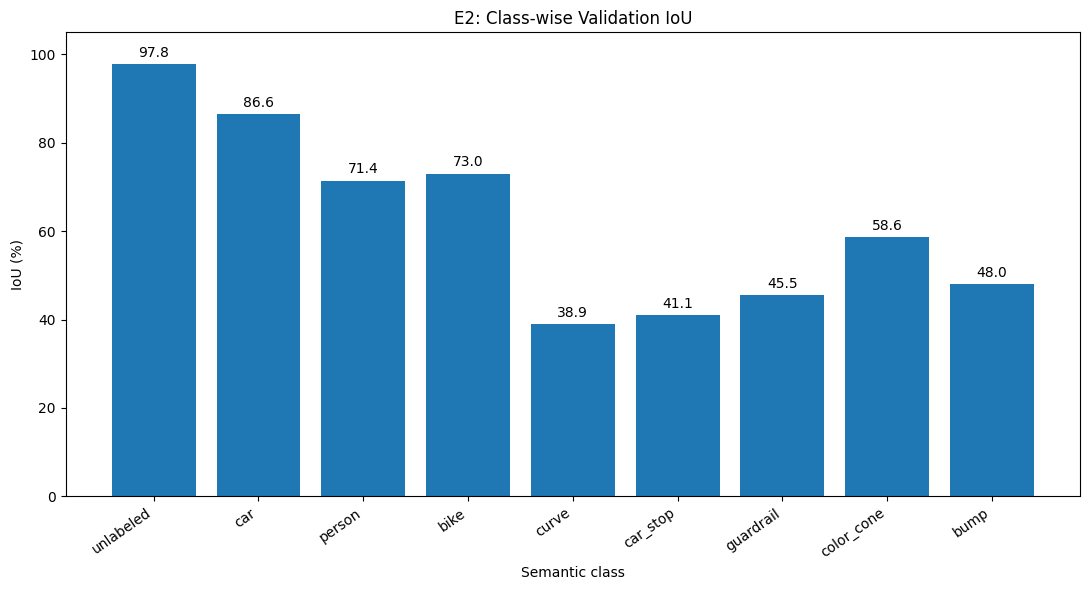

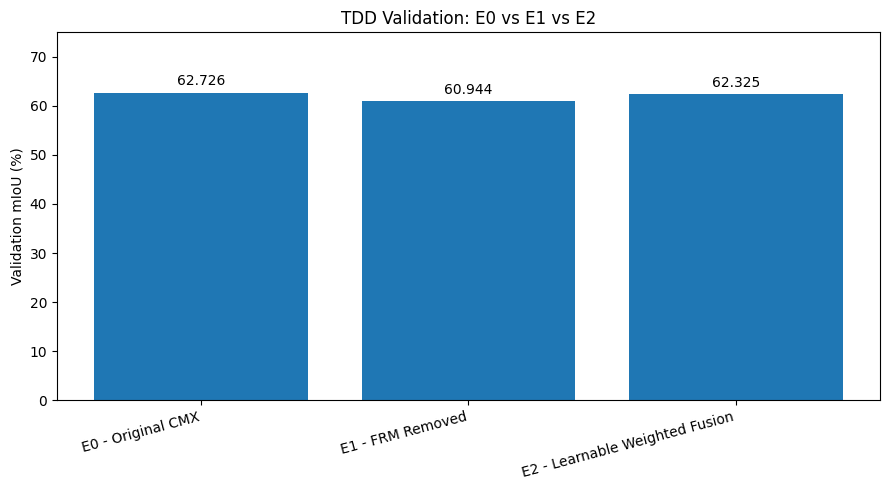

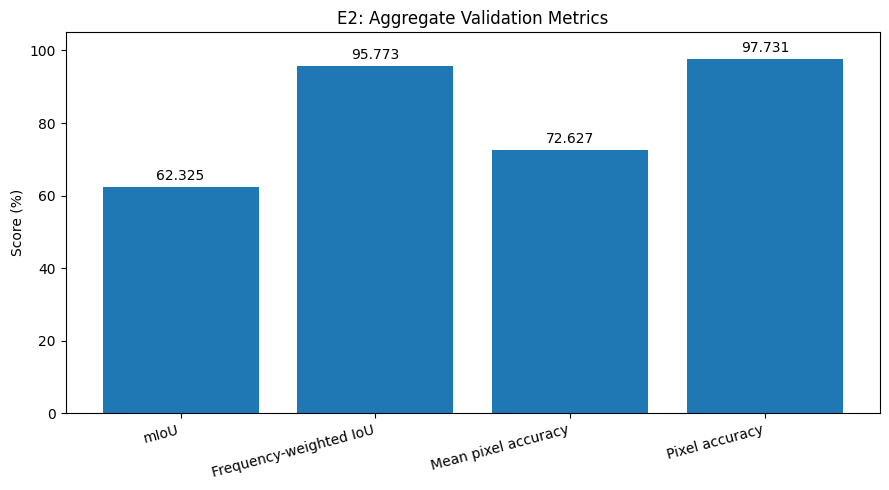


Results saved to: /home/cse-sdpl/Downloads/CMX_E2/results

Class-wise IoU:
     Class  IoU (%)
 unlabeled   97.783
       car   86.555
    person   71.449
      bike   73.042
     curve   38.948
  car_stop   41.058
 guardrail   45.470
color_cone   58.579
      bump   48.038

Experiment mIoU comparison:
                    Experiment  mIoU (%)
             E0 - Original CMX    62.726
              E1 - FRM Removed    60.944
E2 - Learnable Weighted Fusion    62.325


In [45]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Output folder
PROJECT_DIR = Path("/home/cse-sdpl/Downloads/CMX_E2")
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Actual E2 validation results from your evaluation output
classes = [
    "unlabeled", "car", "person", "bike", "curve",
    "car_stop", "guardrail", "color_cone", "bump"
]
ious = [97.783, 86.555, 71.449, 73.042, 38.948,
        41.058, 45.470, 58.579, 48.038]

class_metrics = pd.DataFrame({
    "Class": classes,
    "IoU (%)": ious
})
class_metrics.to_csv(RESULTS_DIR / "E2_classwise_IoU.csv", index=False)

# Save experiment-level mIoU comparison
experiment_metrics = pd.DataFrame({
    "Experiment": ["E0 - Original CMX", "E1 - FRM Removed",
                   "E2 - Learnable Weighted Fusion"],
    "mIoU (%)": [62.726, 60.944, 62.325]
})
experiment_metrics.to_csv(
    RESULTS_DIR / "experiment_mIoU_comparison.csv", index=False
)

# Plot 1: Class-wise IoU
plt.figure(figsize=(11, 6))
bars = plt.bar(class_metrics["Class"], class_metrics["IoU (%)"])
plt.ylabel("IoU (%)")
plt.xlabel("Semantic class")
plt.title("E2: Class-wise Validation IoU")
plt.ylim(0, 105)
plt.xticks(rotation=35, ha="right")
plt.bar_label(bars, fmt="%.1f", padding=3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "E2_classwise_IoU.png", dpi=300)
plt.show()

# Plot 2: mIoU across experiments
plt.figure(figsize=(9, 5))
bars = plt.bar(
    experiment_metrics["Experiment"],
    experiment_metrics["mIoU (%)"]
)
plt.ylabel("Validation mIoU (%)")
plt.title("TDD Validation: E0 vs E1 vs E2")
plt.ylim(0, 75)
plt.xticks(rotation=15, ha="right")
plt.bar_label(bars, fmt="%.3f", padding=3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "experiment_mIoU_comparison.png", dpi=300)
plt.show()

# Plot 3: E2's aggregate metrics
aggregate_metrics = pd.DataFrame({
    "Metric": [
        "mIoU", "Frequency-weighted IoU",
        "Mean pixel accuracy", "Pixel accuracy"
    ],
    "Score (%)": [62.325, 95.773, 72.627, 97.731]
})
aggregate_metrics.to_csv(
    RESULTS_DIR / "E2_aggregate_metrics.csv", index=False
)

plt.figure(figsize=(9, 5))
bars = plt.bar(
    aggregate_metrics["Metric"], aggregate_metrics["Score (%)"]
)
plt.ylabel("Score (%)")
plt.title("E2: Aggregate Validation Metrics")
plt.ylim(0, 105)
plt.xticks(rotation=15, ha="right")
plt.bar_label(bars, fmt="%.3f", padding=3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "E2_aggregate_metrics.png", dpi=300)
plt.show()

print("\nResults saved to:", RESULTS_DIR)
print("\nClass-wise IoU:")
print(class_metrics.to_string(index=False))
print("\nExperiment mIoU comparison:")
print(experiment_metrics.to_string(index=False))


Find and display one prediction

Testing image: 00498D
RGB: /home/cse-sdpl/Downloads/CMX_E2/datasets/TDD/RGB/00498D.png
Thermal: /home/cse-sdpl/Downloads/CMX_E2/datasets/TDD/Thermal/00498D.png
Ground truth: /home/cse-sdpl/Downloads/CMX_E2/datasets/TDD/Label/00498D.png
Prediction: /home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100/00498D.png


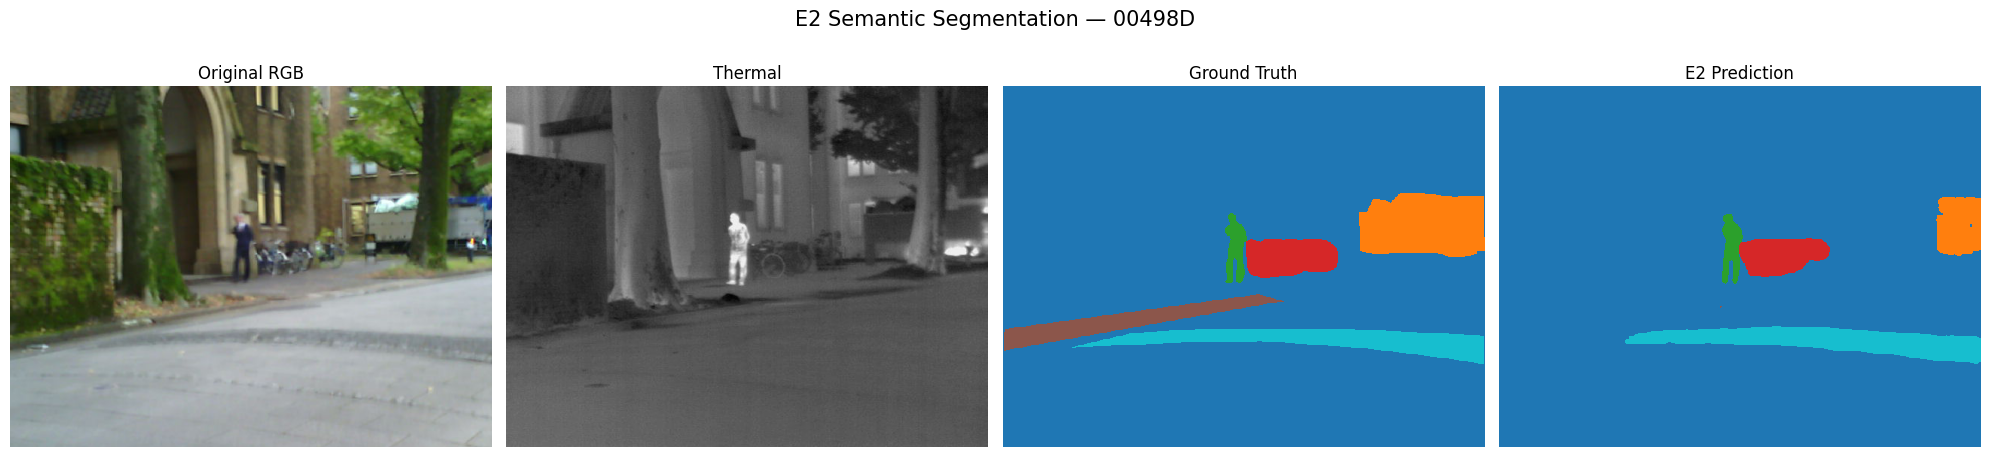

In [47]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

PROJECT_DIR = Path("/home/cse-sdpl/Downloads/CMX_E2")
DATASET_DIR = PROJECT_DIR / "datasets/TDD"
PRED_DIR = PROJECT_DIR / "predictions_TDD_E2_epoch100"

# Select one predicted mask
pred_files = sorted(PRED_DIR.rglob("*.png"))
assert pred_files, f"No predictions found in {PRED_DIR}"

pred_path = pred_files[0]
image_id = pred_path.stem

print("Testing image:", image_id)

# Find corresponding dataset files with the same filename stem
dataset_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".png", ".jpg", ".jpeg"]
    and p.stem == image_id
]

def find_modality(keywords):
    for p in dataset_files:
        parent_names = " ".join(part.lower() for part in p.parts)
        if any(word in parent_names for word in keywords):
            return p
    return None

rgb_path = find_modality(["rgb", "visible"])
thermal_path = find_modality(["thermal", "infrared", "ir"])
gt_path = find_modality(["label", "labels", "mask", "annotation"])

print("RGB:", rgb_path)
print("Thermal:", thermal_path)
print("Ground truth:", gt_path)
print("Prediction:", pred_path)

# Load prediction
prediction = np.array(Image.open(pred_path))

# Create four comparison panels
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

if rgb_path:
    axes[0].imshow(Image.open(rgb_path).convert("RGB"))
    axes[0].set_title("Original RGB")
else:
    axes[0].text(0.5, 0.5, "RGB image not found",
                 ha="center", va="center")
    axes[0].set_title("Original RGB")

if thermal_path:
    axes[1].imshow(Image.open(thermal_path), cmap="gray")
    axes[1].set_title("Thermal")
else:
    axes[1].text(0.5, 0.5, "Thermal image not found",
                 ha="center", va="center")
    axes[1].set_title("Thermal")

if gt_path:
    gt = np.array(Image.open(gt_path))
    axes[2].imshow(gt, cmap="tab10", vmin=0, vmax=8,
                   interpolation="nearest")
    axes[2].set_title("Ground Truth")
else:
    axes[2].text(0.5, 0.5, "Ground truth not found",
                 ha="center", va="center")
    axes[2].set_title("Ground Truth")

axes[3].imshow(prediction, cmap="tab10", vmin=0, vmax=8,
               interpolation="nearest")
axes[3].set_title("E2 Prediction")

for ax in axes:
    ax.axis("off")

fig.suptitle(f"E2 Semantic Segmentation — {image_id}", fontsize=15)
plt.tight_layout()
plt.show()


In [49]:
# Extract the learned fusion weights

In [50]:

from pathlib import Path
import torch

PROJECT_DIR = Path("/home/cse-sdpl/Downloads/CMX_E2")
CHECKPOINT = PROJECT_DIR / "log_TDD_mit_b2_e2/checkpoint/epoch-100.pth"

assert CHECKPOINT.exists(), f"Checkpoint not found: {CHECKPOINT}"

checkpoint = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

    state = checkpoint.get("model", checkpoint.get("state_dict", checkpoint))

    if isinstance(state, dict):
        print("\nPossible fusion parameters:")
        found = False

        for key, value in state.items():
            if "modality_logits" in key:
                found = True
                logits = value.detach().float().reshape(-1)
                weights = torch.softmax(logits, dim=0)

                print(f"\nParameter: {key}")
                print("Learned logits:", logits.tolist())
                print("Softmax weights:", weights.tolist())
                print(f"RGB contribution weight:     {weights[0].item():.4f}")
                print(f"Thermal contribution weight: {weights[1].item():.4f}")

        if not found:
            print(
                "\nNo key containing 'modality_logits' found. "
                "Let's inspect the checkpoint structure before concluding."
            )


Checkpoint type: <class 'dict'>
Checkpoint keys: ['model', 'optimizer', 'epoch', 'iteration']

Possible fusion parameters:

Parameter: backbone.FFMs.0.modality_logits
Learned logits: [0.05976090580224991, -0.05976090952754021]
Softmax weights: [0.5298449397087097, 0.47015509009361267]
RGB contribution weight:     0.5298
Thermal contribution weight: 0.4702

Parameter: backbone.FFMs.1.modality_logits
Learned logits: [0.01100357435643673, -0.011003569699823856]
Softmax weights: [0.5055015683174133, 0.49449843168258667]
RGB contribution weight:     0.5055
Thermal contribution weight: 0.4945

Parameter: backbone.FFMs.2.modality_logits
Learned logits: [-0.02087787538766861, 0.02087787725031376]
Softmax weights: [0.4895625710487366, 0.5104374289512634]
RGB contribution weight:     0.4896
Thermal contribution weight: 0.5104

Parameter: backbone.FFMs.3.modality_logits
Learned logits: [0.02479737438261509, -0.024797379970550537]
Softmax weights: [0.5123961567878723, 0.4876038432121277]
RGB contr